# 1. Median disposable household income by gebied, 2024

In [1]:
import pandas as pd
from IPython.display import display

%pip install openpyxl


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
file_path = "Ggwgebieden.xlsx"

df = pd.read_excel(file_path, sheet_name="data")
metadata = pd.read_excel(file_path, sheet_name="metadata")

# Display the first five observations
df.head()

,Year,Geography,Code,Name,Disposable houshold income (median)
0,2011,ggwgebieden,GA01,Centrum-West,25233
1,2012,ggwgebieden,GA01,Centrum-West,25626
2,2013,ggwgebieden,GA01,Centrum-West,25913
3,2014,ggwgebieden,GA01,Centrum-West,26944
4,2015,ggwgebieden,GA01,Centrum-West,27518


In [3]:
# Select the three variables relevant to the analysis
income_df = df[
    ["Year", "Name", "Disposable houshold income (median)"]
].copy()

# Rename the income column
income_df = income_df.rename(
    columns={
        "Disposable houshold income (median)": 
        "Median disposable household income (€)"
    }
)

income_df.head()

,Year,Name,Median disposable household income (€)
0,2011,Centrum-West,25233
1,2012,Centrum-West,25626
2,2013,Centrum-West,25913
3,2014,Centrum-West,26944
4,2015,Centrum-West,27518


Now we will examine the number of observations, years, and  geographical areas. This confirms whether the dataset corresponds to the expected period of 2011–2024 and contains the 25 GGW areas of Amsterdam. 

In [4]:
print("Number of observations:", len(income_df))
print("Number of GGW areas:", income_df["Name"].nunique())
print("Number of years:", income_df["Year"].nunique())
print("First year:", income_df["Year"].min())
print("Most recent year:", income_df["Year"].max())

print("\nData types:")
print(income_df.dtypes)

Number of observations: 339
Number of GGW areas: 25
Number of years: 14
First year: 2011
Most recent year: 2024

Data types:
Year                                      int64
Name                                        str
Median disposable household income (€)    int64
dtype: object


"Year" is indeed a numerical and discrete temporal variable, "Name" as categorical/nominal, and income as a numerical variable.

# Data visualization
The following bar chart provides a visualization of the median disposable household income across the 25 neighborhoods in 2024. The areas are ordered from highest to lowest median income to make differences between neighborhoods easier to observe.

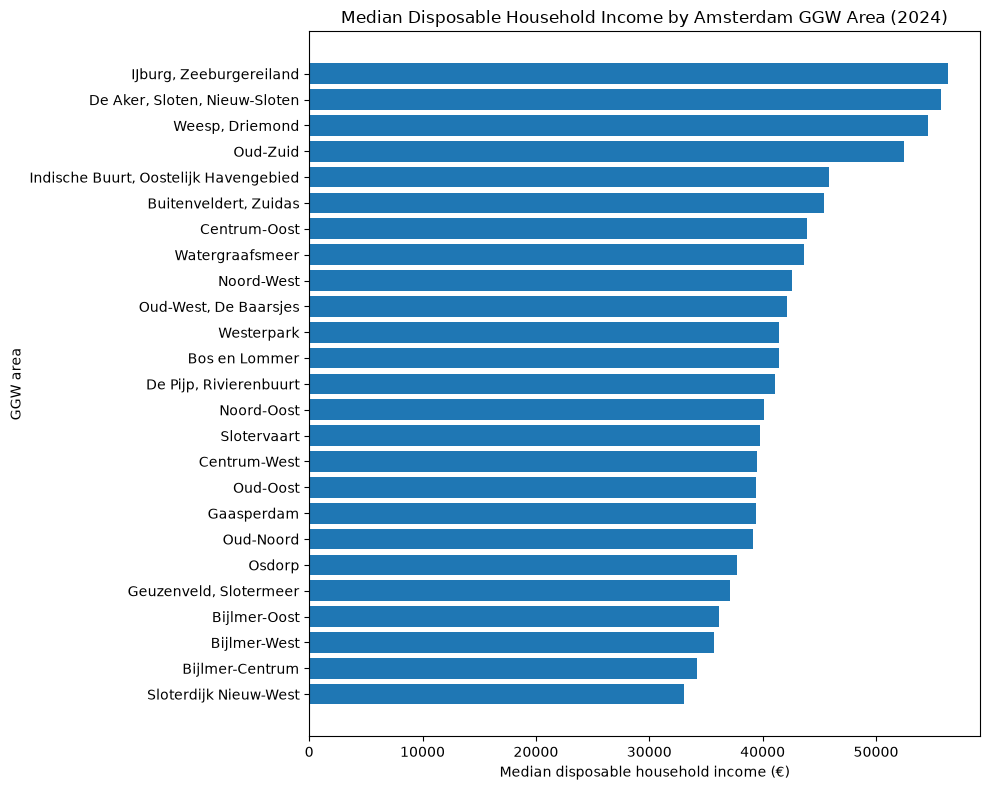

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the 2024 observations and sort by income
income_2024 = (
    income_df[income_df["Year"] == 2024]
    .sort_values(
        by="Median disposable household income (€)",
        ascending=True
    )
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 8))

plt.barh(
    income_2024["Name"],
    income_2024["Median disposable household income (€)"]
)

plt.xlabel("Median disposable household income (€)")
plt.ylabel("GGW area")
plt.title("Median Disposable Household Income by Amsterdam GGW Area (2024)")

plt.tight_layout()
plt.show()

# Missing values 

In [6]:
# Create all possible combinations of years and GGW areas
all_years = range(2011, 2025)
all_areas = income_df["Name"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_years, all_areas],
    names=["Year", "Name"]
)

# Reindex the dataset so that absent year-area combinations appear as NaN
complete_df = (
    income_df
    .set_index(["Year", "Name"])
    .reindex(complete_index)
    .reset_index()
)

# Identify missing observations
missing_data = complete_df[
    complete_df["Median disposable household income (€)"].isna()
]

print("Number of missing year-area observations:", len(missing_data))
print()
print(missing_data[["Year", "Name"]].to_string(index=False))

Number of missing year-area observations: 11

 Year                  Name
 2011 Sloterdijk Nieuw-West
 2011          Bijlmer-West
 2012 Sloterdijk Nieuw-West
 2012          Bijlmer-West
 2013 Sloterdijk Nieuw-West
 2013          Bijlmer-West
 2014 Sloterdijk Nieuw-West
 2014          Bijlmer-West
 2015 Sloterdijk Nieuw-West
 2016 Sloterdijk Nieuw-West
 2017 Sloterdijk Nieuw-West


There are 11 missing year-area observations: Bijlmer-West has no observations between 2011-2014, while Sloterdijk 
Nieuw-West has no observations between 2011-2017.

# 2. Education HBO, WO (%) in Amsterdam 

In [7]:
import pandas as pd 
import matplotlib.pyplot as plt

In [8]:
file_path = "Education levels.xlsx"

education = pd.read_excel(
    file_path,
    sheet_name="data",
    engine="openpyxl"
)

metadata = pd.read_excel(
    file_path,
    sheet_name="metadata",
    engine="openpyxl"
)

education.head()

,Year,Geography,Code,Name,"education hbo, wo (%)"
0,2021,ggwgebieden,GA02,Centrum-Oost,62
1,2021,ggwgebieden,GK12,"Buitenveldert, Zuidas",54
2,2021,ggwgebieden,GK11,Oud-Zuid,66
3,2021,ggwgebieden,GF10,Slotervaart,41
4,2021,ggwgebieden,GA01,Centrum-West,62


In [9]:
education_df = education[
    ["Year", "Name", "education hbo, wo (%)"]]

print("Number of observations:", len(education_df))
print("Number of GGW areas:", education_df["Name"].nunique())
print("Number of years:", education_df["Year"].nunique())
print("First year:", education_df["Year"].min())
print("Most recent year:", education_df["Year"].max())

print("\nData types:")
print(education_df.dtypes)

Number of observations: 356
Number of GGW areas: 25
Number of years: 15
First year: 2010
Most recent year: 2024

Data types:
Year                     int64
Name                       str
education hbo, wo (%)    int64
dtype: object


This verifies and confirms the correct number of areas (25) and the period of the dataset (2010-2024). This also supports the description of the relevant variables: "Year", "Name", and "Education". 

# Missing data
We will investigate all possible combinations of years and areas to identify the missing observations. 

In [10]:
all_years = range(2010, 2025)
all_areas = education_df["Name"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_years, all_areas],
    names=["Year", "Name"]
)

# Add absent combinations as missing values
complete_df = (
    education_df
    .set_index(["Year", "Name"])
    .reindex(complete_index)
    .reset_index()
)

# Select missing observations
missing_data = complete_df[
    complete_df["education hbo, wo (%)"].isna()
]

print("Number of missing year-area observations:", len(missing_data))
print()

print(
    missing_data
    .groupby("Name")["Year"]
    .apply(list)
)

Number of missing year-area observations: 19

Name
Bijlmer-West                         [2010, 2011, 2012, 2013, 2014]
Sloterdijk Nieuw-West    [2010, 2011, 2012, 2013, 2014, 2015, 2016]
Weesp, Driemond          [2010, 2011, 2012, 2013, 2014, 2015, 2016]
Name: Year, dtype: object


We also want to confirm that all 25 GGW areas contain an education value for 2024 because it is the most recent year available. The following code will check this and for any missing values. 

In [11]:
education_2024 = education_df[
    education_df["Year"] == 2024
].copy()

print("Number of GGW areas in 2024:", education_2024["Name"].nunique())
print(
    "Missing education values in 2024:",
    education_2024["education hbo, wo (%)"].isna().sum()
)

Number of GGW areas in 2024: 25
Missing education values in 2024: 0


# Checking for any outliers 
Potential outliers are examined using the interquartile range (IQR) method. An observation is considered a potential outlier if it falls below
Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR. 

In [12]:
Q1 = education_2024["education hbo, wo (%)"].quantile(0.25)
Q3 = education_2024["education hbo, wo (%)"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = education_2024[
    (education_2024["education hbo, wo (%)"] < lower_bound) |
    (education_2024["education hbo, wo (%)"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))

Lower bound: 3.0
Upper bound: 91.0
Number of potential outliers: 0


Therefore, we can confirm that there are no outliers for the 2024 values. 

# Data visualization 
The following graph compares the % of residents aged 15–74 with a completed HBO or WO education across the 25 Amsterdam GGW areas in 2024.

The horiztonal line represents the municipality's reported citywide Amsterdam value of 49%. This makes it possible to compare individual GGW areas with the citywide percentage.

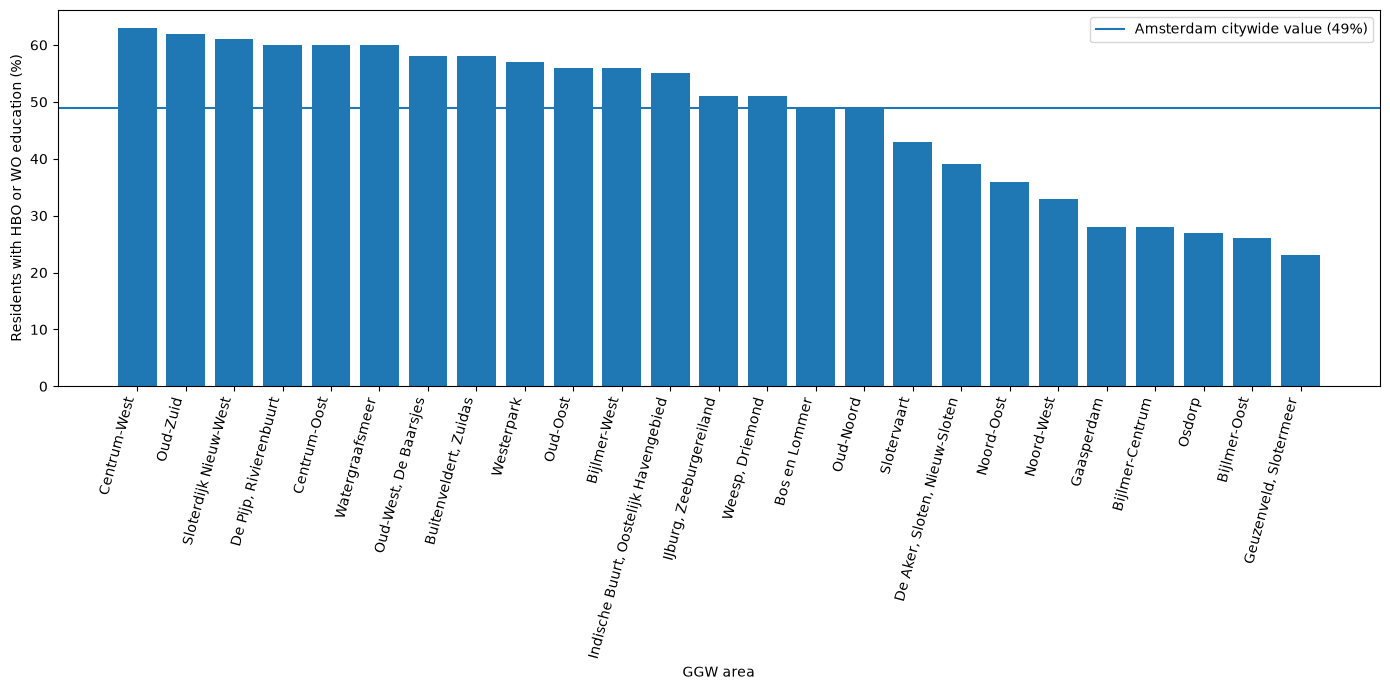

In [13]:
# Sort areas from lowest to highest education percentage
education_2024_sorted = education_2024.sort_values(
    by="education hbo, wo (%)",
    ascending=False
)

plt.figure(figsize=(14, 7))

plt.bar(
    education_2024_sorted["Name"],
    education_2024_sorted["education hbo, wo (%)"]
)

# Add the Amsterdam citywide percentage
plt.axhline(
    y=49,
    linestyle="-",
    label="Amsterdam citywide value (49%)"
)

plt.xlabel("GGW area")
plt.ylabel("Residents with HBO or WO education (%)")
plt.xticks(rotation=75, ha="right")

plt.legend()
plt.tight_layout()

plt.show()

# 3. Inside Airbnb

In [14]:
import numpy as np
import pandas as pd


In [15]:
data_airbnb = pd.read_csv("listings.csv.gz")

In [16]:
print(data_airbnb.head())

      id                         listing_url       scrape_id last_scraped  \
0  28871  https://www.airbnb.com/rooms/28871  20260615212022   2026-06-16   
1  29051  https://www.airbnb.com/rooms/29051  20260615212022   2026-06-16   
2  44129  https://www.airbnb.com/rooms/44129  20260615212022   2026-06-24   
3  44391  https://www.airbnb.com/rooms/44391  20260615212022   2026-06-24   
4  48373  https://www.airbnb.com/rooms/48373  20260615212022   2026-06-24   

            source                                             name  \
0  previous scrape                          Comfortable double room   
1  previous scrape                 Comfortable single / double room   
2  previous scrape                    Luxury design with canal view   
3  previous scrape  Quiet 2-bedroom Amsterdam city centre apartment   
4  previous scrape              Cozy family home in Amsterdam South   

                                         description  neighborhood_overview  \
0          Basic bedroom in the

In [17]:
df.shape

(339, 5)

The data set includes 10369 observations each observation represents one listing on airbnb. The data set also includes 90 coloumns each representing a different variable. 

In [18]:
for i, col in enumerate(df.columns, 1):
    print(i, col)

1 Year
2 Geography
3 Code
4 Name
5 Disposable houshold income (median)


for the purpose of convenience let's establish these 90 varaibles into distinct categories:
1. listing identification (1-10)
2. host charactarestics (11-33)
3. neighbourhood info (34-38), this catgory is important for our specefied project proposal
4. property charactarestics (39-46), this category also might prove important 
5. price information (47-52), this is the most important group because price is our target variable 
6. booking restrictions and stay charactarestics (53-61)
7. Availability, reviews and estimated activity (62-83)
8. other info (84-90)

In [19]:
data_airbnb.dtypes

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 90, dtype: object

In [20]:
data_airbnb[['price', 'room_type', 'property_type', 'accommodates',
    'bathrooms', 'bedrooms', 'beds', 'minimum_nights',
    'number_of_reviews', 'review_scores_rating']].describe(include='all')

,price,room_type,property_type,accommodates,bathrooms,bedrooms,beds,minimum_nights,number_of_reviews,review_scores_rating
count,6377,10369,10369,10369.000000,5413.000000,9219.000000,5717.000000,10366.000000,10369.000000,9346.000000
unique,2709,4,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,$314.00,Entire home/apt,Entire rental unit,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,44,8489,4451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2.941364,1.248014,1.634234,1.903096,3.591646,51.703539,4.850425
std,NaN,NaN,NaN,1.278998,0.529313,0.890917,1.533525,14.112109,143.771159,0.243524
min,NaN,NaN,NaN,1.000000,0.500000,0.000000,1.000000,1.000000,0.000000,1.000000
25%,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,1.000000,3.000000,4.800000
50%,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,2.000000,10.000000,4.920000
75%,NaN,NaN,NaN,4.000000,1.500000,2.000000,2.000000,3.000000,32.000000,5.000000


In [21]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing) 

# the above code allows us to ispect which varaibles have non zero missing values ordered from most to least 

Series([], dtype: int64)


Important missing varaibles:

1. bathrooms                        4956
2. beds                             4652
3. price                            3992
4. price_quote_price_per_night      3992
5. estimated_revenue_l365d          3992
6. price_quote_total_price          3992
7. price_quote_raw                  3861
8. bedrooms                         1150



In [22]:
data_airbnb[data_airbnb['price'].isna()][
    ['id','has_availability','availability_365','price','price_quote_price_per_night']
].head(20)


,id,has_availability,availability_365,price,price_quote_price_per_night
1,29051,t,2,NaN,NaN
3,44391,t,0,NaN,NaN
4,48373,t,0,NaN,NaN
8,53921,t,0,NaN,NaN
9,55868,t,0,NaN,NaN
11,80635,t,0,NaN,NaN
15,155548,t,0,NaN,NaN
17,168769,t,0,NaN,NaN
18,171054,t,0,NaN,NaN
22,190943,t,0,NaN,NaN


In [23]:
data_airbnb[data_airbnb['price'].isna()]['availability_365'].mean()

np.float64(6.424599198396794)

<Axes: ylabel='Frequency'>

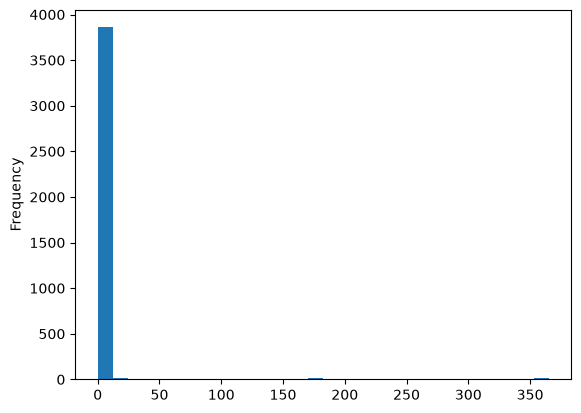

In [24]:
import matplotlib.pyplot as plt

data_airbnb[data_airbnb['price'].isna()]['availability_365'].plot.hist(bins=30)



The graph illustrates that the overwhelming majority of listings with a missing price have an availablity that gravitates around the number 0 which provides insight into the reason why the data is missing in the first place.

In [25]:
data_airbnb['id'].duplicated().sum()

np.int64(0)

No duplicate IDs which is a good sign 

In [26]:
data_airbnb['minimum_nights'].describe()

count    10366.000000
mean         3.591646
std         14.112109
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        800.000000
Name: minimum_nights, dtype: float64

a potential issue we might have to investigate is the max of 800

<Axes: ylabel='Frequency'>

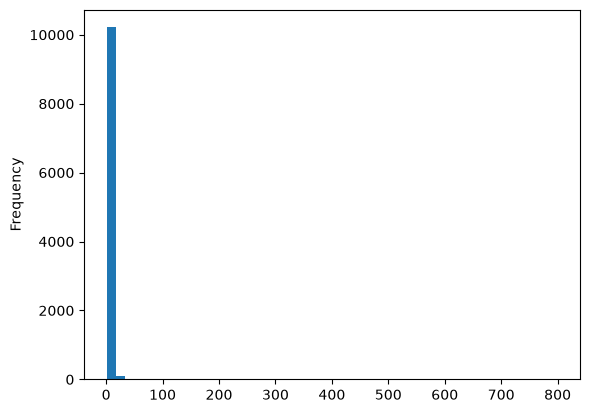

In [27]:
data_airbnb['minimum_nights'].plot.hist(bins=50)

In [28]:
data_airbnb['minimum_nights'].value_counts().sort_index(ascending=False).head(20)

minimum_nights
800.0     1
365.0     3
364.0     2
363.0     2
300.0     1
299.0     1
180.0     1
100.0     1
99.0      1
90.0     23
80.0      1
75.0      1
60.0      1
55.0      1
50.0      1
48.0      1
45.0      2
40.0      1
31.0      3
30.0     30
Name: count, dtype: int64

In [29]:
price_numeric = (
    data_airbnb['price']
    .str.replace('$', '')
    .str.replace(',', '')
    .astype(float)
)
price_numeric.describe()

count     6377.000000
mean       346.621932
std        327.297968
min         14.700000
25%        206.670000
50%        291.000000
75%        411.000000
max      11412.000000
Name: price, dtype: float64

<Axes: ylabel='Frequency'>

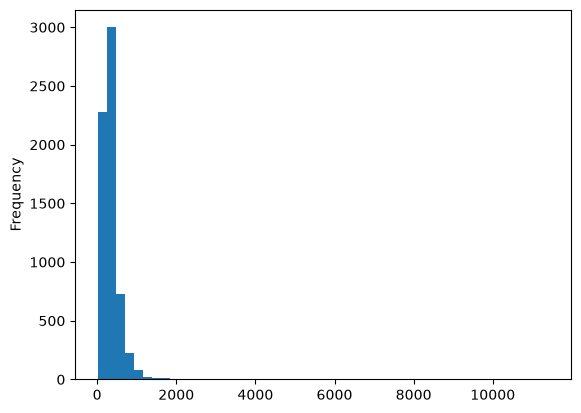

In [30]:
price_numeric.plot.hist(bins=50)

skewed right

In [31]:
price_numeric.sort_values(ascending=False).head(20)

9551     11412.00
373      11411.80
4364      7200.00
4499      7200.00
3491      5706.00
6267      3382.60
10292     3025.00
10310     2700.00
1502      2477.00
6350      2354.00
10081     2304.40
9300      2282.50
4957      2277.00
384       2029.71
9699      1912.00
8964      1887.00
2598      1854.50
4504      1854.50
1920      1826.00
9696      1797.35
Name: price, dtype: float64

In [32]:
data_airbnb.loc[
    price_numeric.nlargest(20).index,
    [
        "price",
        "host_id",
        "property_type",
        "room_type",
        "accommodates",
        "minimum_nights",
        "bedrooms",
        "bathrooms",
        "beds",
        "neighbourhood_cleansed",
        "listing_url"
    ]
]

,price,host_id,property_type,room_type,accommodates,minimum_nights,bedrooms,bathrooms,beds,neighbourhood_cleansed,listing_url
9551,"$11,412.00",182912442,Entire home,Entire home/apt,4,1.0,2.0,1.0,2.0,De Pijp - Rivierenbuurt,https://www.airbnb.com/rooms/1548025772403046607
373,"$11,411.80",10428722,Entire rental unit,Entire home/apt,2,5.0,1.0,1.0,1.0,Centrum-West,https://www.airbnb.com/rooms/2474754
4364,"$7,200.00",18081564,Boat,Entire home/apt,16,1.0,7.0,2.0,22.0,Oud-Noord,https://www.airbnb.com/rooms/612289973482163299
4499,"$7,200.00",18081564,Boat,Entire home/apt,16,1.0,17.0,17.0,30.0,Oud-Noord,https://www.airbnb.com/rooms/643315499225242586
3491,"$5,706.00",264906709,Entire rental unit,Entire home/apt,2,5.0,1.0,1.0,2.0,Zuid,https://www.airbnb.com/rooms/42910448
6267,"$3,382.60",534378749,Entire home,Entire home/apt,8,3.0,4.0,3.5,4.0,Centrum-West,https://www.airbnb.com/rooms/968203403339639631
10292,"$3,025.00",718508838,Casa particular,Entire home/apt,2,1.0,1.0,1.0,1.0,Centrum-West,https://www.airbnb.com/rooms/1693616534399481978
10310,"$2,700.00",691780400,Entire home,Entire home/apt,8,1.0,4.0,4.5,5.0,Centrum-West,https://www.airbnb.com/rooms/1698438915127575870
1502,"$2,477.00",1791317,Houseboat,Entire home/apt,4,1.0,3.0,2.0,6.0,Centrum-Oost,https://www.airbnb.com/rooms/15304003
6350,"$2,354.00",538035047,Entire loft,Entire home/apt,4,1.0,3.0,NaN,3.0,Centrum-West,https://www.airbnb.com/rooms/984625805593041593


This displays the top 20 Airbnb listings with the highest numeric prices together with the other selected listing characteristics, such as the property type, host ID number, etc. 

# 4. Merging the datasets
Firstly, the 3 datasets have different units of observation. The Inside Airbnb dataset contains one observation per Airbnb listing, while the income and education datasets contain one observation per GGW area and year. 

To combine the datasets without accidentally duplicating the Airbnb listings across multiple years, we will use the 2024 observations from the income and education datasets, because it is most recent year. 

The 2024 income and education values will first be combined at the GGW area level. These neighborhood-level characteristics will then be added to each Airbnb listing, based on the listing's 'neighbourhood_cleansed' variable. 

The income and education variables should be interpreted as the most recently available neighborhood characteristics, instead of measurements from the same year as the Airbnb data (2026). 

In [33]:
# Preparing the income dataset for merging
income_merge = (
    income_df.loc[
        income_df["Year"] == 2024,
        ["Name", "Median disposable household income (€)"]
    ]
    .rename(columns={"Name": "GGW_area_income"})
    .copy()
)

education_merge = (
    education_df.loc[
        education_df["Year"] == 2024,
        ["Name", "education hbo, wo (%)"]
    ]
    .rename(
        columns={
            "Name": "GGW_area_education",
            "education hbo, wo (%)": "Higher education (HBO/WO) (%)"
        }
    )
    .copy()
)

def normalize_area_name(name):
    return " ".join(
        name.lower()
        .replace("-", " ")
        .replace(",", " ")
        .split()
    )

income_merge["area_key"] = income_merge["GGW_area_income"].map(normalize_area_name)
education_merge["area_key"] = education_merge["GGW_area_education"].map(normalize_area_name)

socio_2024 = income_merge.merge(
    education_merge,
    on="area_key",
    how="outer",
    validate="one_to_one",
    indicator=True
)

print("Merge result:")
print(socio_2024["_merge"].value_counts())

socio_2024["GGW_area"] = (
    socio_2024["GGW_area_income"]
    .combine_first(socio_2024["GGW_area_education"])
)

socio_2024 = socio_2024[
    [
        "area_key",
        "GGW_area",
        "Median disposable household income (€)",
        "Higher education (HBO/WO) (%)"
    ]
].copy()


Merge result:
_merge
both          25
left_only      0
right_only     0
Name: count, dtype: int64


In [34]:
airbnb_area_key_corrections = {
    "De Baarsjes - Oud-West": "oud west de baarsjes",
    "Oostelijk Havengebied - Indische Buurt":
        "indische buurt oostelijk havengebied",
    "De Aker - Nieuw Sloten": "de aker sloten nieuw sloten",
}

airbnb_for_merge = data_airbnb.copy()

airbnb_for_merge["area_key"] = (
    airbnb_for_merge["neighbourhood_cleansed"]
    .map(airbnb_area_key_corrections)
)

unmapped_keys = airbnb_for_merge["area_key"].isna()

airbnb_for_merge.loc[unmapped_keys, "area_key"] = (
    airbnb_for_merge.loc[
        unmapped_keys, "neighbourhood_cleansed"
    ].map(normalize_area_name)
)

assert socio_2024["area_key"].is_unique

merged_df = airbnb_for_merge.merge(
    socio_2024,
    on="area_key",
    how="left",
    validate="many_to_one",
    indicator="_socio_merge"
)


In [35]:
print("Airbnb listings before merge:", len(airbnb_for_merge))
print("Rows after merge:", len(merged_df))

print("\nMerge results:")
print(merged_df["_socio_merge"].value_counts())

print(
    "\nPercentage matched:",
    round(merged_df["_socio_merge"].eq("both").mean() * 100, 2),
    "%"
)

print("\nUnmatched Airbnb neighbourhoods:")
print(
    merged_df.loc[
        merged_df["_socio_merge"] == "left_only",
        "neighbourhood_cleansed"
    ].value_counts()
)

assert len(merged_df) == len(airbnb_for_merge)
assert merged_df["id"].is_unique


Airbnb listings before merge: 10369
Rows after merge: 10369

Merge results:
_socio_merge
both          9621
left_only      748
right_only       0
Name: count, dtype: int64

Percentage matched: 92.79 %

Unmatched Airbnb neighbourhoods:
neighbourhood_cleansed
Zuid                     694
Gaasperdam - Driemond     54
Name: count, dtype: int64


## Part 4.1: Validating the neighnourhood data merge 

In the prevouis part we merged the different data sets, but some neighbourhoods appear to not have matched. we need to check wether the unmapped areas correspond to areas in the socioeconomic dataset 

In [36]:
print("Airbnb neighbourhoods:")
print(sorted(data_airbnb["neighbourhood_cleansed"].dropna().unique()))

print("\nSocioeconomic neighbourhoods:")
print(sorted(socio_2024["area_key"].dropna().unique()))

Airbnb neighbourhoods:
['Bijlmer-Centrum', 'Bijlmer-Oost', 'Bos en Lommer', 'Buitenveldert - Zuidas', 'Centrum-Oost', 'Centrum-West', 'De Aker - Nieuw Sloten', 'De Baarsjes - Oud-West', 'De Pijp - Rivierenbuurt', 'Gaasperdam - Driemond', 'Geuzenveld - Slotermeer', 'IJburg - Zeeburgereiland', 'Noord-Oost', 'Noord-West', 'Oostelijk Havengebied - Indische Buurt', 'Osdorp', 'Oud-Noord', 'Oud-Oost', 'Slotervaart', 'Watergraafsmeer', 'Westerpark', 'Zuid']

Socioeconomic neighbourhoods:
['bijlmer centrum', 'bijlmer oost', 'bijlmer west', 'bos en lommer', 'buitenveldert zuidas', 'centrum oost', 'centrum west', 'de aker sloten nieuw sloten', 'de pijp rivierenbuurt', 'gaasperdam', 'geuzenveld slotermeer', 'ijburg zeeburgereiland', 'indische buurt oostelijk havengebied', 'noord oost', 'noord west', 'osdorp', 'oud noord', 'oud oost', 'oud west de baarsjes', 'oud zuid', 'sloterdijk nieuw west', 'slotervaart', 'watergraafsmeer', 'weesp driemond', 'westerpark']


The two neighbourhoods dont have an exact match in the socio economic data set. a potential approach of fitting them into the official data is comparing the longitude and latidue of the listings in the airbnb data set with the official with GGW area boundries.

In [37]:
print(data_airbnb[["neighbourhood_cleansed", "latitude", "longitude"]].head())

print(
    data_airbnb.loc[
        data_airbnb["neighbourhood_cleansed"].isin(
            ["Zuid", "Gaasperdam - Driemond"]
        ),
        ["neighbourhood_cleansed", "latitude", "longitude"]
    ].isna().sum()
)

   neighbourhood_cleansed   latitude  longitude
0            Centrum-West  52.367750    4.89092
1            Centrum-Oost  52.365840    4.89111
2            Centrum-West  52.382110    4.88630
3            Centrum-Oost  52.371680    4.91471
4  Buitenveldert - Zuidas  52.327808    4.87680
neighbourhood_cleansed    0
latitude                  0
longitude                 0
dtype: int64


In [38]:
import json

with open("gebieden-ggwgebieden-2026-10-11T14_29_11.531231+02_00.json") as f:
    ggw_data = json.load(f)

print(ggw_data)

{'type': 'FeatureCollection', 'crs': {'type': 'name', 'properties': {'name': 'urn:ogc:def:crs:OGC::CRS84'}}, 'features': [{'type': 'Feature', 'id': 'ggwgebieden.03630950000022.3', 'geometry': {'type': 'Polygon', 'coordinates': [[[4.879180121757535, 52.36525887812909], [4.879131004410987, 52.365379920825134], [4.879064280592781, 52.36549989029438], [4.878954380552377, 52.365661781893834], [4.878811589819747, 52.365832798505004], [4.87869524903772, 52.36594544539348], [4.878528818069729, 52.366079312698965], [4.878391849017578, 52.36617132470711], [4.878131473961563, 52.36630815807488], [4.877883731654975, 52.3664648002457], [4.877720341054487, 52.36658668087468], [4.87751272183099, 52.36677026038059], [4.877425288934914, 52.366951579869315], [4.877343593095821, 52.36718171837212], [4.87731392234066, 52.36729899728509], [4.877259839894671, 52.36770061464848], [4.877193150201885, 52.367896053123644], [4.877082759020611, 52.368105926302746], [4.876803577672635, 52.36850153121973], [4.87667

In [39]:
print(ggw_data["features"][0]["properties"]["naam"])

Centrum-West


In [40]:
print(ggw_data["features"][0]["geometry"]["type"])
print(ggw_data["features"][0]["geometry"]["coordinates"][0][:5])

Polygon
[[4.879180121757535, 52.36525887812909], [4.879131004410987, 52.365379920825134], [4.879064280592781, 52.36549989029438], [4.878954380552377, 52.365661781893834], [4.878811589819747, 52.365832798505004]]


we need to create a function that creates a boundry for each of the specefied boundries in the GWW data, then that same function checks weather the unassigned observation falls within that boundry we created. This makes sure that we dont accidently assign an observation to the wrong neighbourhood.

In [41]:
def point_in_polygon(lon, lat, polygon): #defines our function that takes three arguments from the airbnb dataset 
    inside = False

    for i in range(len(polygon)): # this loop allows us to sort through all coordinate pairs  in polygon
        x1, y1 = polygon[i] # this assigns x1 to logtitude and y1 to latitude at each i (iteration)
        x2, y2 = polygon[(i + 1) % len(polygon)] # this line then gets another point and assigns x2 and y2, and the list bit makes sure it is connected back to the first point when we reach the final iteration

        if (y1 > lat) != (y2 > lat): # this condition checks wether on boundry point is above the listing's latiude and the other is not. 
            intersection_x = x1 + (lat - y1) * (x2 - x1) / (y2 - y1)

            if lon < intersection_x:
                inside = not inside

    return inside

polygon = [
    [4, 52],
    [6, 52],
    [6, 54],
    [4, 54]
]

print(point_in_polygon(5, 53, polygon))
print(point_in_polygon(7, 53, polygon))

True
False


In [42]:
def find_ggw_area(lon, lat):
    for feature in ggw_data["features"]:
        polygon = feature["geometry"]["coordinates"]

        if point_in_polygon(lon, lat, polygon[0]):
            return feature["properties"]["naam"]

    return None

In [43]:
print(find_ggw_area(
    data_airbnb.loc[0, "longitude"],
    data_airbnb.loc[0, "latitude"]
))

Centrum-West


the function correctly identfies the neighbourhood of the first listing's location as centrum west, the function works as intended 

In [44]:
def get_area(row):
    return find_ggw_area(row["longitude"], row["latitude"])


data_airbnb["ggw_area"] = data_airbnb.apply(get_area, axis=1)

In [45]:
print(
    data_airbnb[
        data_airbnb["neighbourhood_cleansed"].isin(
            ["Zuid", "Gaasperdam - Driemond"]
        )
    ].groupby(
        ["neighbourhood_cleansed", "ggw_area"],
        dropna=False
    ).size()
)

neighbourhood_cleansed  ggw_area       
Gaasperdam - Driemond   Gaasperdam          47
                        Weesp, Driemond      7
Zuid                    Oud-Zuid           694
dtype: int64


In [46]:
print(data_airbnb["ggw_area"].isna().sum())

0


In [47]:
merged_df = data_airbnb.merge(
    socio_2024,
    left_on="ggw_area",
    right_on="GGW_area",
    how="left"
)

In [48]:
print("Airbnb rows:", len(data_airbnb))
print("Merged rows:", len(merged_df))

print(
    "Missing income:",
    merged_df["Median disposable household income (€)"].isna().sum()
)

print(
    "Missing education:",
    merged_df["Higher education (HBO/WO) (%)"].isna().sum()
)

merged_df.head()

Airbnb rows: 10369
Merged rows: 10369
Missing income: 0
Missing education: 0


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,ggw_area,area_key,GGW_area,Median disposable household income (€),Higher education (HBO/WO) (%)
0,28871,https://www.airbnb.com/rooms/28871,20260615212022,2026-06-16,previous scrape,Comfortable double room,Basic bedroom in the center of Amsterdam.,NaN,https://a0.muscache.com/pictures/160889/362340...,124245,...,2,0,2,0,4.15,Centrum-West,centrum west,Centrum-West,39545,63
1,29051,https://www.airbnb.com/rooms/29051,20260615212022,2026-06-16,previous scrape,Comfortable single / double room,This room can also be rented as a single or a ...,NaN,https://a0.muscache.com/pictures/162009/bd6be2...,124245,...,2,0,2,0,4.88,Centrum-Oost,centrum oost,Centrum-Oost,43924,60
2,44129,https://www.airbnb.com/rooms/44129,20260615212022,2026-06-24,previous scrape,Luxury design with canal view,"Welcome to my little gem<br /><br />Cozy, brig...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,187728,...,4,3,1,0,0.96,Centrum-West,centrum west,Centrum-West,39545,63
3,44391,https://www.airbnb.com/rooms/44391,20260615212022,2026-06-24,previous scrape,Quiet 2-bedroom Amsterdam city centre apartment,Guests greatly appreciate the unique location ...,NaN,https://a0.muscache.com/pictures/97741545/3900...,194779,...,1,1,0,0,0.22,Centrum-Oost,centrum oost,Centrum-Oost,43924,60
4,48373,https://www.airbnb.com/rooms/48373,20260615212022,2026-06-24,previous scrape,Cozy family home in Amsterdam South,Charming modern apartment in the quiet and gre...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,220434,...,1,1,0,0,0.14,"Buitenveldert, Zuidas",buitenveldert zuidas,"Buitenveldert, Zuidas",45456,58


In [63]:
# 1. Confirm that no Airbnb listings were added or lost
assert len(merged_df) == len(data_airbnb)

# 2. Confirm that listing IDs remain unique
assert merged_df["id"].is_unique

# 3. Confirm that every listing has socioeconomic data
assert merged_df["Median disposable household income (€)"].notna().all()
assert merged_df["Higher education (HBO/WO) (%)"].notna().all()

# 4. Check the number of assigned GGW areas
print("Unique assigned GGW areas:", merged_df["GGW_area"].nunique())
print(merged_df["GGW_area"].value_counts().sort_index())

Unique assigned GGW areas: 25
GGW_area
Bijlmer-Centrum                            47
Bijlmer-Oost                               39
Bijlmer-West                               15
Bos en Lommer                             539
Buitenveldert, Zuidas                     121
Centrum-Oost                              955
Centrum-West                             1157
De Aker, Sloten, Nieuw-Sloten              71
De Pijp, Rivierenbuurt                   1193
Gaasperdam                                 47
Geuzenveld, Slotermeer                    140
IJburg, Zeeburgereiland                   188
Indische Buurt, Oostelijk Havengebied     410
Noord-Oost                                179
Noord-West                                312
Osdorp                                     59
Oud-Noord                                 474
Oud-Oost                                  664
Oud-West, De Baarsjes                    1818
Oud-Zuid                                  694
Sloterdijk Nieuw-West                    

In [65]:
expected_areas = set(socio_2024["GGW_area"])
assigned_areas = set(merged_df["GGW_area"].dropna())

print("Expected areas:", len(expected_areas))
print("Assigned areas:", len(assigned_areas))
print("Unexpected areas:", assigned_areas - expected_areas)
print("Unrepresented areas:", expected_areas - assigned_areas)

assert len(merged_df) == len(data_airbnb)
assert merged_df["id"].is_unique
assert merged_df["GGW_area"].notna().all()
assert merged_df["Median disposable household income (€)"].notna().all()
assert merged_df["Higher education (HBO/WO) (%)"].notna().all()
assert assigned_areas == expected_areas

print("All merge validation checks passed.")

Expected areas: 25
Assigned areas: 25
Unexpected areas: set()
Unrepresented areas: set()
All merge validation checks passed.


The datasets have different units of observation: each Airbnb observation represents one listing, while the socioeconomic variables are measured at the GGW area level. Since the neighbourhood names did not always match, listings were assigned to GGW areas using their geographical coordinates and official boundary polygons. The 2024 socioeconomic data was then merged with the Airbnb dataset. The merge preserved all 10,369 observations, covered all 25 GGW areas, and resulted in no missing income or education values.

In [67]:
(
    merged_df["ggw_area"] == merged_df["GGW_area"]
).all()

np.True_

In [68]:
merged_df = merged_df.drop(columns=["ggw_area"]) # removes the redundant column

## Part 4.2: Converting Airbnb prices to numerical values 
The Airbnb 'price' variable contains currency symbols and commas and is therefore stored as a text variable. Earlier in the analysis, these characters were removed to convert the listing prices into numerical values.

Since all of the datasets have now been merged, the same conversion is applied directly to the 'price' column in 'merged_df'. A new variable, 'price_numeric', is created so that Airbnb prices can be used in subsequent statistical analyses and predictive models while the original 'price' variable is retained.

In [49]:

merged_df["price_numeric"] = (
    merged_df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Check the numerical price variable
merged_df["price_numeric"].describe()

count     6377.000000
mean       346.621932
std        327.297968
min         14.700000
25%        206.670000
50%        291.000000
75%        411.000000
max      11412.000000
Name: price_numeric, dtype: float64

'describe()' automatically excludes missing values, so a count of 6,039 means that there are 6,039 listings with an available numerical price. 

In [50]:
print("Total Airbnb listings:", len(merged_df))
print("Listings with a price:", merged_df["price_numeric"].notna().sum())
print("Listings without a price:", merged_df["price_numeric"].isna().sum())

Total Airbnb listings: 10369
Listings with a price: 6377
Listings without a price: 3992


The `price` column contains Airbnb's nightly listing prices, represented in local currency. For the Amsterdam dataset, these values are interpreted as euros (€). The dollar sign in the exported data is a formatting artifact, so it is removed along with thousands separators to convert the prices into numerical values. No currency conversion is performed.

The resulting variable, `price_numeric`, contains 6,377 non-missing prices out of 10,369 listings. The remaining 3,992 listings have missing price values.

# 5. Exploratory data analysis

This section explores the listing-level variables that may help predict Airbnb prices. The analysis uses `merged_df`, which already contains the neighbourhood socioeconomic information joined using the geographic matching approach established in Part 4. The merge is not repeated here.

The target variable is `price_numeric`. Listings without an observed price cannot be used as target observations in supervised price prediction, although they remain part of the full dataset for descriptive checks.

## 5.1 Create a focused analysis dataset

Keep the variables relevant to the research question in a smaller dataframe. `merged_df` remains unchanged as the full merged dataset. The selection below keeps only columns that are available in the current merged dataframe, avoiding assumptions about duplicate merge columns.

In [51]:
columns_to_keep = [
    "id",
    "price_numeric",
    "room_type",
    "property_type",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "minimum_nights",
    "neighbourhood_cleansed",
    "ggw_area",
    "GGW_area",
    "latitude",
    "longitude",
    "Median disposable household income (€)",
    "Higher education (HBO/WO) (%)"
]

analysis_columns = [col for col in columns_to_keep if col in merged_df.columns]
analysis_df = merged_df[analysis_columns].copy()

print("Analysis dataset dimensions:", analysis_df.shape)
analysis_df.info()

Analysis dataset dimensions: (10369, 16)
<class 'pandas.DataFrame'>
RangeIndex: 10369 entries, 0 to 10368
Data columns (total 16 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   id                                      10369 non-null  int64  
 1   price_numeric                           6377 non-null   float64
 2   room_type                               10369 non-null  str    
 3   property_type                           10369 non-null  str    
 4   accommodates                            10369 non-null  int64  
 5   bedrooms                                9219 non-null   float64
 6   beds                                    5717 non-null   float64
 7   bathrooms                               5413 non-null   float64
 8   minimum_nights                          10366 non-null  float64
 9   neighbourhood_cleansed                  10369 non-null  str    
 10  ggw_area                    

## 5.2 Assess missing values

First, inspect missing values in the variables selected for analysis. Missing listing prices matter because price is the prediction target. Missing bedrooms, beds, or bathrooms may affect which predictors can be used in a model. Missing socioeconomic variables would indicate a neighbourhood-level match issue, which should be interpreted in light of the geographic matching completed in Part 4.

In [52]:
missing = analysis_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

bathrooms         4956
beds              4652
price_numeric     3992
bedrooms          1150
minimum_nights       3
dtype: int64

In [53]:
def calculate_missing_percentage(group):
    return group.isna().mean() * 100

room_characteristics = [
    col for col in ["bedrooms", "beds", "bathrooms"]
    if col in analysis_df.columns
]

if "room_type" in analysis_df.columns and room_characteristics:
    missing_by_room = (
        analysis_df.groupby("room_type")[room_characteristics]
        .apply(calculate_missing_percentage)
        .round(1)
    )
    display(missing_by_room)

,bedrooms,beds,bathrooms
room_type,,,
Entire home/apt,1.8,48.7,50.6
Hotel room,3.8,0.0,0.0
Private room,54.1,27.9,35.5
Shared room,28.6,9.5,28.6


In [54]:
if "room_type" in analysis_df.columns:
    missing_price_by_room = (
        analysis_df.groupby("room_type")["price_numeric"]
        .apply(lambda x: x.isna().mean() * 100)
        .round(1)
    )
    display(missing_price_by_room.rename("Missing price (%)"))

room_type
Entire home/apt    43.8
Hotel room          0.0
Private room       14.9
Shared room         0.0
Name: Missing price (%), dtype: float64

## 5.3 Examine the price distribution and potential outliers

The distribution of observed nightly prices is examined before modelling. Airbnb prices are often right-skewed, so a small number of expensive listings can make the distribution difficult to read. The IQR rule is used to flag potential outliers for inspection, not to automatically classify them as errors or remove them.

count     6377.000000
mean       346.621932
std        327.297968
min         14.700000
25%        206.670000
50%        291.000000
75%        411.000000
max      11412.000000
Name: price_numeric, dtype: float64

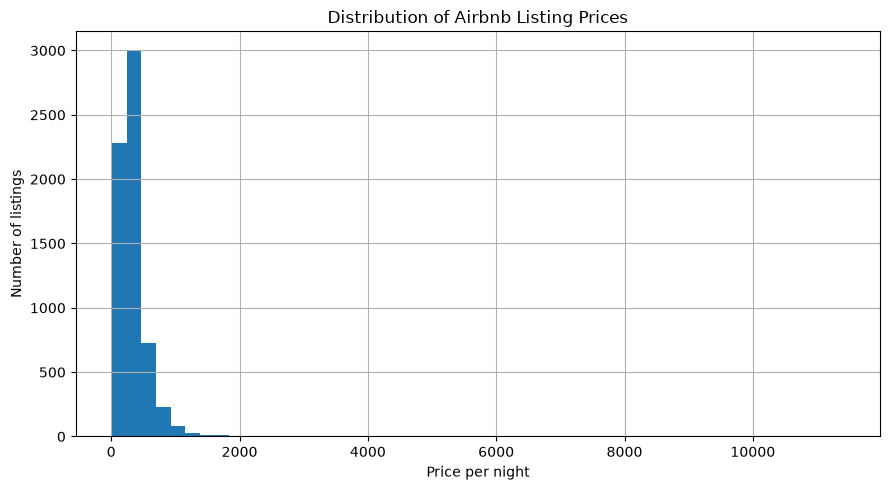

In [55]:
price_summary = analysis_df["price_numeric"].describe()
display(price_summary)

plt.figure(figsize=(9, 5))
analysis_df["price_numeric"].dropna().hist(bins=50)
plt.xlabel("Price per night")
plt.ylabel("Number of listings")
plt.title("Distribution of Airbnb Listing Prices")
plt.tight_layout()
plt.show()

In [56]:
priced_listings = analysis_df["price_numeric"].dropna()

Q1 = priced_listings.quantile(0.25)
Q3 = priced_listings.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_low = priced_listings[priced_listings < lower_bound]
outliers_high = priced_listings[priced_listings > upper_bound]

print("IQR lower bound:", lower_bound)
print("IQR upper bound:", upper_bound)
print("Potential low outliers:", len(outliers_low))
print("Potential high outliers:", len(outliers_high))

IQR lower bound: -99.82500000000002
IQR upper bound: 717.495
Potential low outliers: 0
Potential high outliers: 343


In [57]:
outlier_columns = [
    col for col in [
        "price_numeric", "room_type", "property_type",
        "accommodates", "bedrooms"
    ]
    if col in analysis_df.columns
]

display(
    analysis_df.nlargest(10, "price_numeric")[outlier_columns]
)

,price_numeric,room_type,property_type,accommodates,bedrooms
9551,11412.0,Entire home/apt,Entire home,4,2.0
373,11411.8,Entire home/apt,Entire rental unit,2,1.0
4364,7200.0,Entire home/apt,Boat,16,7.0
4499,7200.0,Entire home/apt,Boat,16,17.0
3491,5706.0,Entire home/apt,Entire rental unit,2,1.0
6267,3382.6,Entire home/apt,Entire home,8,4.0
10292,3025.0,Entire home/apt,Casa particular,2,1.0
10310,2700.0,Entire home/apt,Entire home,8,4.0
1502,2477.0,Entire home/apt,Houseboat,4,3.0
6350,2354.0,Entire home/apt,Entire loft,4,3.0


In [58]:
if "property_type" in analysis_df.columns:
    display(
        analysis_df.groupby("property_type")["price_numeric"]
        .agg(["count", "median", "max"])
        .sort_values("max", ascending=False)
        .head(10)
    )

high_price_count = (analysis_df["price_numeric"] > 1000).sum()
priced_count = analysis_df["price_numeric"].notna().sum()

print("Listings priced above 1,000:", high_price_count)
if priced_count:
    print(
        "Share of listings with observed prices above 1,000:",
        round(high_price_count / priced_count * 100, 2),
        "%"
    )

,count,median,max
property_type,,,
Entire home,707,375.000,11412.0
Entire rental unit,2457,314.000,11411.8
Boat,90,322.335,7200.0
Casa particular,4,443.405,3025.0
Houseboat,127,410.000,2477.0
Entire loft,141,361.000,2354.0
Entire condo,906,346.750,2304.4
Entire villa,10,522.805,2282.5
Entire guesthouse,37,208.000,1912.0


Listings priced above 1,000: 107
Share of listings with observed prices above 1,000: 1.68 %


Potential outliers should not be removed solely because they exceed the IQR threshold. They may reflect luxury properties, unusual listing characteristics, or data quality issues. Any exclusion or transformation should be justified and applied consistently before model evaluation.

## 5.4 Compare prices by room type

Compare the price distributions across room types using a boxplot. A second view omits plotted outlier points and limits the y-axis to make the central distributions easier to compare. The underlying observations are not removed from the dataset.

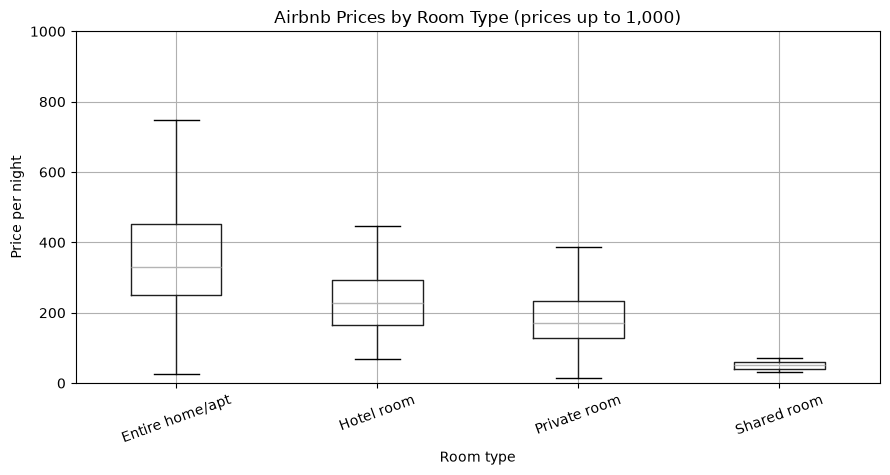

,count,median,mean
room_type,,,
Entire home/apt,4771,331.00,394.54
Hotel room,26,227.50,249.91
Private room,1559,172.33,205.18
Shared room,21,52.00,80.09


In [59]:
if "room_type" in analysis_df.columns:
    analysis_df.boxplot(
        column="price_numeric",
        by="room_type",
        figsize=(9, 5),
        showfliers=False
    )
    plt.ylim(0, 1000)
    plt.xlabel("Room type")
    plt.ylabel("Price per night")
    plt.title("Airbnb Prices by Room Type (prices up to 1,000)")
    plt.suptitle("")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    display(
        analysis_df.groupby("room_type")["price_numeric"]
        .agg(["count", "median", "mean"])
        .round(2)
        .sort_values("median", ascending=False)
    )

## 5.5 Explore listing capacity and bedrooms

Accommodation capacity and bedroom count are plausible predictors of price. Scatterplots help reveal the overall relationship and its variability. Because extreme prices can obscure the main pattern, the y-axis is restricted to 1,000 for readability; this changes only the display, not the data used in calculations.

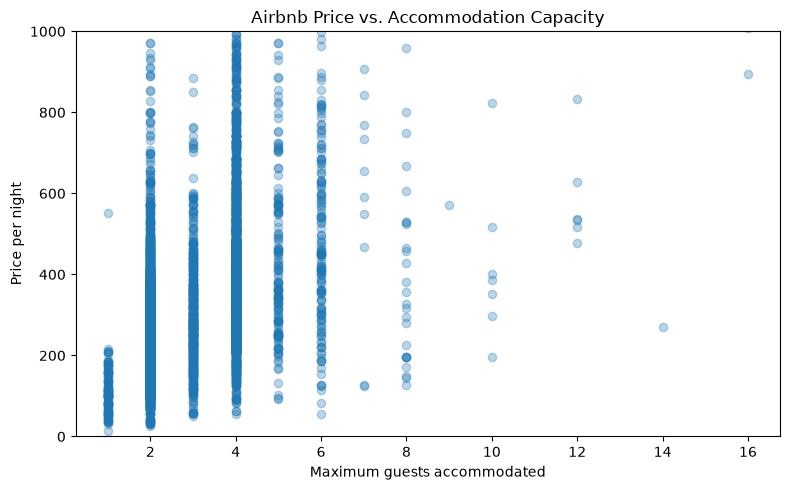

,accommodates,price_numeric
accommodates,1.000000,0.385421
price_numeric,0.385421,1.000000


In [60]:
if "accommodates" in analysis_df.columns:
    plt.figure(figsize=(8, 5))
    plt.scatter(
        analysis_df["accommodates"],
        analysis_df["price_numeric"],
        alpha=0.3
    )
    plt.ylim(0, 1000)
    plt.xlabel("Maximum guests accommodated")
    plt.ylabel("Price per night")
    plt.title("Airbnb Price vs. Accommodation Capacity")
    plt.tight_layout()
    plt.show()

    display(analysis_df[["accommodates", "price_numeric"]].corr())

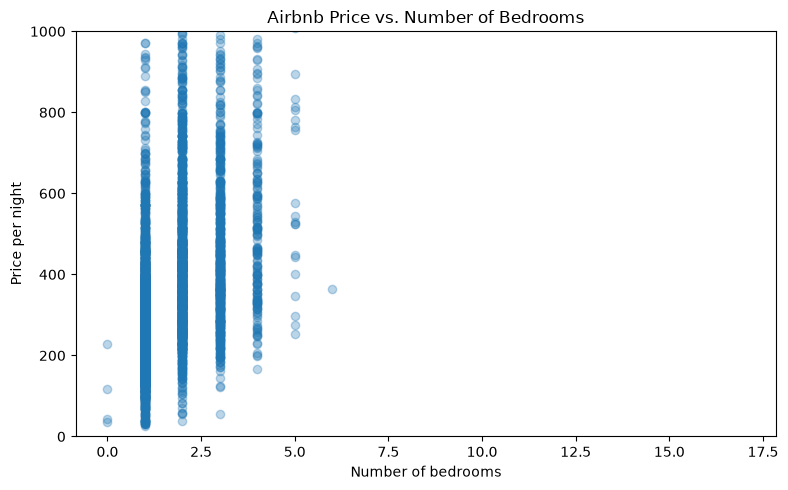

,bedrooms,price_numeric
bedrooms,1.000000,0.381162
price_numeric,0.381162,1.000000


In [61]:
if "bedrooms" in analysis_df.columns:
    plt.figure(figsize=(8, 5))
    plt.scatter(
        analysis_df["bedrooms"],
        analysis_df["price_numeric"],
        alpha=0.3
    )
    plt.ylim(0, 1000)
    plt.xlabel("Number of bedrooms")
    plt.ylabel("Price per night")
    plt.title("Airbnb Price vs. Number of Bedrooms")
    plt.tight_layout()
    plt.show()

    display(analysis_df[["bedrooms", "price_numeric"]].corr())

## 5.6 Compare prices across Airbnb neighbourhoods

This descriptive comparison uses Airbnb's own `neighbourhood_cleansed` categories. It is separate from the official GGW area assignment used to attach socioeconomic data. Neighbourhoods with very few priced listings can have unstable median estimates, so the listing count should be considered alongside the median.

,count,median
neighbourhood_cleansed,,
De Pijp - Rivierenbuurt,696,335.56
Zuid,435,334.00
De Baarsjes - Oud-West,1066,330.49
Centrum-West,851,297.52
Centrum-Oost,666,287.79
Westerpark,402,287.50
IJburg - Zeeburgereiland,116,286.88
Watergraafsmeer,178,285.56
Oud-Oost,383,277.00


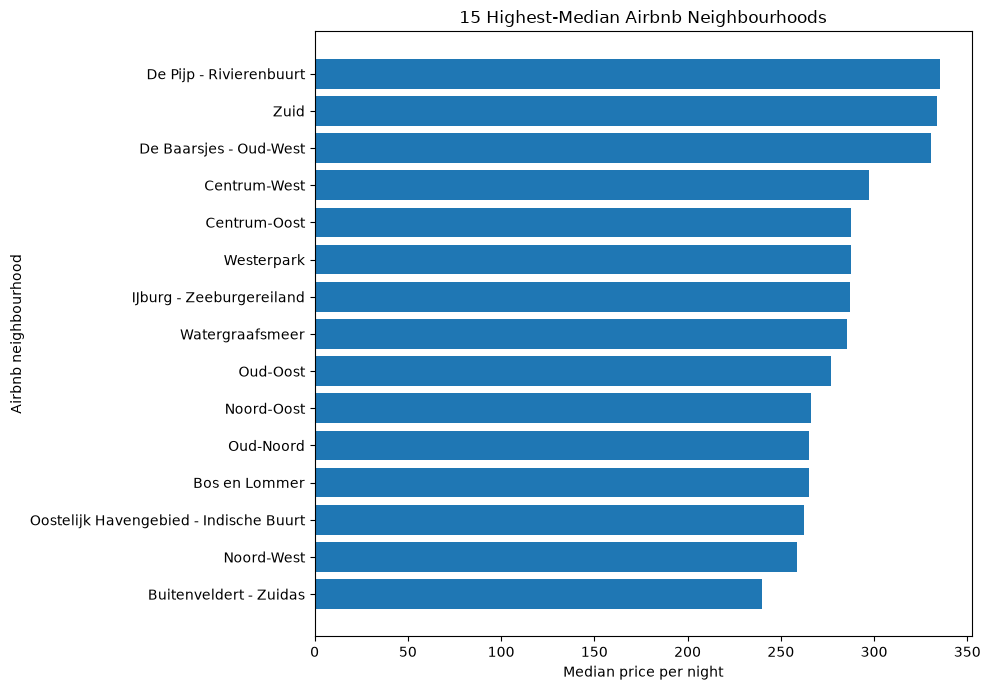

In [62]:
if "neighbourhood_cleansed" in analysis_df.columns:
    neighbourhood_prices = (
        analysis_df.groupby("neighbourhood_cleansed")["price_numeric"]
        .agg(["count", "median"])
        .sort_values("median", ascending=False)
    )
    display(neighbourhood_prices.head(15).round(2))

    # Show the 15 neighbourhoods with the highest observed median prices.
    plot_data = neighbourhood_prices.head(15).sort_values("median")
    plt.figure(figsize=(10, 7))
    plt.barh(plot_data.index.astype(str), plot_data["median"])
    plt.xlabel("Median price per night")
    plt.ylabel("Airbnb neighbourhood")
    plt.title("15 Highest-Median Airbnb Neighbourhoods")
    plt.tight_layout()
    plt.show()

## Part 5.7: Explore prices alongside socioeconomic characteristics 

In [69]:

ggw_summary = (
    merged_df
    .dropna(subset=["price_numeric"])
    .groupby("GGW_area", as_index=False)
    .agg(
        median_price=("price_numeric", "median"),
        listing_count=("price_numeric", "count"),
        median_income=("Median disposable household income (€)", "first"),
        higher_education_pct=("Higher education (HBO/WO) (%)", "first")
    )
)

ggw_summary.head()


,GGW_area,median_price,listing_count,median_income,higher_education_pct
0,Bijlmer-Centrum,148.105,32,34190,28
1,Bijlmer-Oost,120.305,24,36108,26
2,Bijlmer-West,222.400,15,35717,56
3,Bos en Lommer,265.000,257,41424,49
4,"Buitenveldert, Zuidas",240.650,88,45456,58


In [70]:
ggw_summary.sort_values("median_price", ascending=False)

,GGW_area,median_price,listing_count,median_income,higher_education_pct
20,Sloterdijk Nieuw-West,387.000,1,33036,61
8,"De Pijp, Rivierenbuurt",335.860,695,41125,60
19,Oud-Zuid,334.000,435,52464,62
18,"Oud-West, De Baarsjes",330.490,1066,42109,58
6,Centrum-West,300.200,825,39545,63
24,Westerpark,287.500,402,41486,57
22,Watergraafsmeer,285.560,178,43622,60
11,"IJburg, Zeeburgereiland",285.500,117,56355,51
5,Centrum-Oost,284.750,692,43924,60
17,Oud-Oost,277.000,383,39455,56


Before running a correlation code there seems to be a relationship between 'higher_education_pct' and 'median_price. My prediction is that the relationship is strong 

In [71]:
education_price_corr = ggw_summary[
    ["median_price", "higher_education_pct"]
].corr().iloc[0, 1]

print(
    "Correlation between median Airbnb price and "
    f"higher education: {education_price_corr:.3f}"
)

Correlation between median Airbnb price and higher education: 0.802


this result provides preliminary evidence relevant to Research Question 1: neighbourhoods with higher shares of residents with higher education tend to have higher median Airbnb prices in this sample.

In [79]:
income_price_corr = ggw_summary[
    ["median_price", "median_income"]
].corr().iloc[0, 1]

print(
    "Correlation between median Airbnb price and "
    f"median household income: {income_price_corr:.3f}"
)

Correlation between median Airbnb price and median household income: 0.214


higher education is often associated with higher earnings at the individual level. If neighbourhoods with higher education levels also tend to have higher household incomes, then why is education strongly correlated with Airbnb prices (\(r=0.802\)), while income has a much weaker correlation (\(r=0.214\))?

In [80]:

education_income_corr = ggw_summary[
    ["median_income", "higher_education_pct"]
].corr().iloc[0, 1]

print(
    "Correlation between median household income and "
    f"higher education: {education_income_corr:.3f}"
)


Correlation between median household income and higher education: 0.263


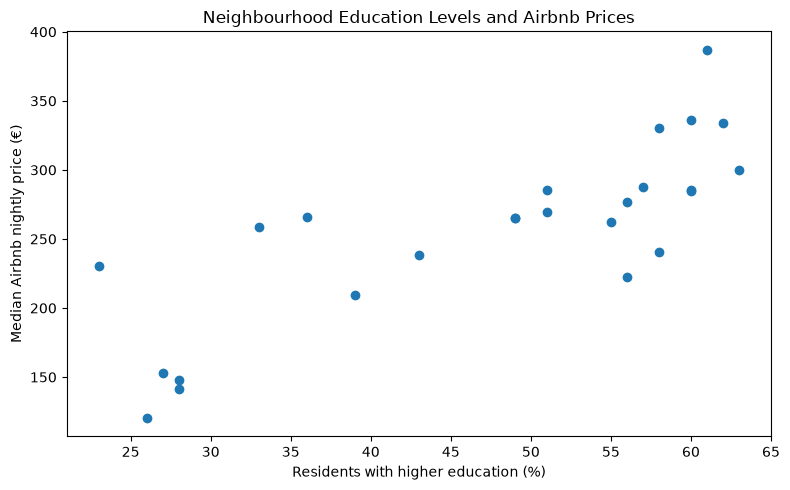

In [81]:

plt.figure(figsize=(8, 5))

plt.scatter(
    ggw_summary["higher_education_pct"],
    ggw_summary["median_price"]
)

plt.xlabel("Residents with higher education (%)")
plt.ylabel("Median Airbnb nightly price (€)")
plt.title("Neighbourhood Education Levels and Airbnb Prices")

plt.tight_layout()
plt.show()


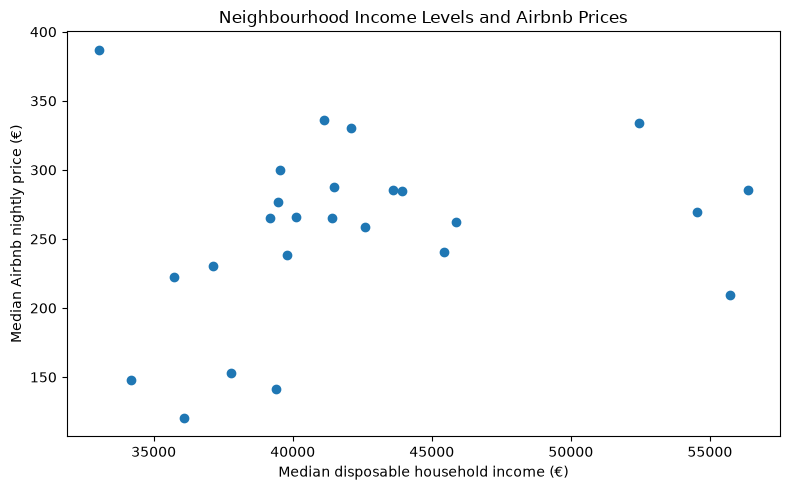

In [82]:

plt.figure(figsize=(8, 5))

plt.scatter(
    ggw_summary["median_income"],
    ggw_summary["median_price"]
)

plt.xlabel("Median disposable household income (€)")
plt.ylabel("Median Airbnb nightly price (€)")
plt.title("Neighbourhood Income Levels and Airbnb Prices")

plt.tight_layout()
plt.show()


Our preliminary finding is that higher-education percentage has a much stronger neighbourhood-level association with Airbnb prices than median household income does.


Some areas have few listings it would be wise to test the relationship while exdluding said areas

In [83]:

small_areas = (
    ggw_summary[ggw_summary["listing_count"] < 10]
    .sort_values("listing_count")
)

print("Number of areas with fewer than 10 priced listings:",
      len(small_areas))

small_areas[
    ["GGW_area", "listing_count", "median_price"]
]


Number of areas with fewer than 10 priced listings: 2


,GGW_area,listing_count,median_price
20,Sloterdijk Nieuw-West,1,387.0
23,"Weesp, Driemond",5,269.4


In [ ]:

ggw_summary_filtered = ggw_summary[
    ggw_summary["listing_count"] >= 10
].copy()

# Excludes GGW areas with fewer than 10 priced listings

print("GGW areas retained:", len(ggw_summary_filtered))

# Recalculate all three correlations
filtered_correlations = ggw_summary_filtered[
    ["median_price", "higher_education_pct", "median_income"]
].corr()

print("\nFiltered correlations:")
print(
    "Median price vs higher education:",
    round(filtered_correlations.loc[
        "median_price", "higher_education_pct"
    ], 3)
)

print(
    "Median price vs median income:",
    round(filtered_correlations.loc[
        "median_price", "median_income"
    ], 3)
)

print(
    "Median income vs higher education:",
    round(filtered_correlations.loc[
        "median_income", "higher_education_pct"
    ], 3)
)


GGW areas retained: 23

Filtered correlations:
Median price vs higher education: 0.805
Median price vs median income: 0.404
Median income vs higher education: 0.355


 revised preliminary finding is that higher education has a consistently strong positive neighbourhood-level association with median Airbnb prices, while the income–price relationship is more sensitive to the inclusion of areas with very few priced listings.

 Overall, higher-education percentage shows a stronger and more robust neighbourhood-level association with median Airbnb prices than median household income in this descriptive analysis. However, these are correlations across a relatively small number of neighbourhoods, and they do not establish causation. Differences in location, tourism demand, listing characteristics and other neighbourhood factors may also contribute to the observed patterns.